# 🔍 Model Comparison & Classification (Unit 3 + 4)
Compare all regression models and add a bonus classification view.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, confusion_matrix, classification_report, roc_auc_score)
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')
df_clean = df.drop_duplicates().reset_index(drop=True)

X = df_clean.drop('quality', axis=1)
y = df_clean['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# Train all models
models = {
    'Simple LR': (LinearRegression().fit(X_train_scaled[['alcohol']], y_train), X_test_scaled[['alcohol']]),
    'Multiple LR': (LinearRegression().fit(X_train_scaled, y_train), X_test_scaled),
    'Ridge': (Ridge(alpha=1.0).fit(X_train_scaled, y_train), X_test_scaled),
    'Lasso': (Lasso(alpha=0.01).fit(X_train_scaled, y_train), X_test_scaled),
    'ElasticNet': (ElasticNet(alpha=0.01, l1_ratio=0.5).fit(X_train_scaled, y_train), X_test_scaled),
}

# Evaluate
all_results = []
for name, (model, X_te) in models.items():
    y_pred = model.predict(X_te)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    all_results.append({'Model': name, 'MAE': round(mae,4), 'MSE': round(mse,4),
                        'RMSE': round(rmse,4), 'R2_Score': round(r2,4)})
    print(f"{name}: R²={r2:.4f}, RMSE={rmse:.4f}")

print("\n✅ All models trained")

Simple LR: R²=0.2421, RMSE=0.7327
Multiple LR: R²=0.3915, RMSE=0.6565
Ridge: R²=0.3918, RMSE=0.6564
Lasso: R²=0.3995, RMSE=0.6522
ElasticNet: R²=0.3987, RMSE=0.6526

✅ All models trained


## Cell 19: Model Comparison (Unit 3)

MODEL COMPARISON - WINE QUALITY PREDICTION
      Model    MAE    MSE   RMSE  R2_Score
  Simple LR 0.5675 0.5368 0.7327    0.2421
Multiple LR 0.5041 0.4310 0.6565    0.3915
      Ridge 0.5041 0.4308 0.6564    0.3918
      Lasso 0.5012 0.4254 0.6522    0.3995
 ElasticNet 0.5018 0.4259 0.6526    0.3987


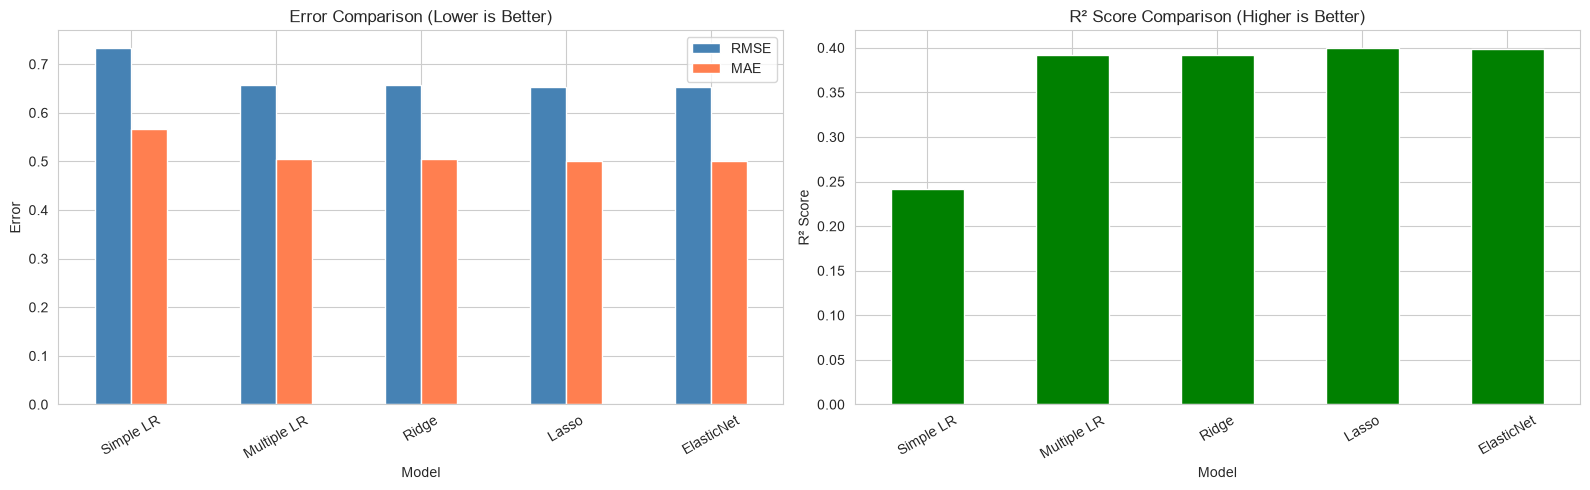


🏆 Best Model: Lasso
   R² Score: 0.3995
   RMSE: 0.6522


In [21]:
# Unit 3: Compare all regression models

comparison_df = pd.DataFrame(all_results)
print("MODEL COMPARISON - WINE QUALITY PREDICTION")
print("=" * 70)
print(comparison_df.to_string(index=False))

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

comparison_df.set_index('Model')[['RMSE', 'MAE']].plot(kind='bar', ax=axes[0], 
                                                        color=['steelblue', 'coral'])
axes[0].set_title('Error Comparison (Lower is Better)')
axes[0].set_ylabel('Error')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(['RMSE', 'MAE'])

comparison_df.set_index('Model')['R2_Score'].plot(kind='bar', ax=axes[1], color='green')
axes[1].set_title('R² Score Comparison (Higher is Better)')
axes[1].set_ylabel('R² Score')
axes[1].tick_params(axis='x', rotation=30)
axes[1].axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

# Identify best model
best_idx = comparison_df['R2_Score'].idxmax()
print(f"\n🏆 Best Model: {comparison_df.loc[best_idx, 'Model']}")
print(f"   R² Score: {comparison_df.loc[best_idx, 'R2_Score']}")
print(f"   RMSE: {comparison_df.loc[best_idx, 'RMSE']}")

## Cell 20: Actual vs Predicted - All Models (Unit 3)

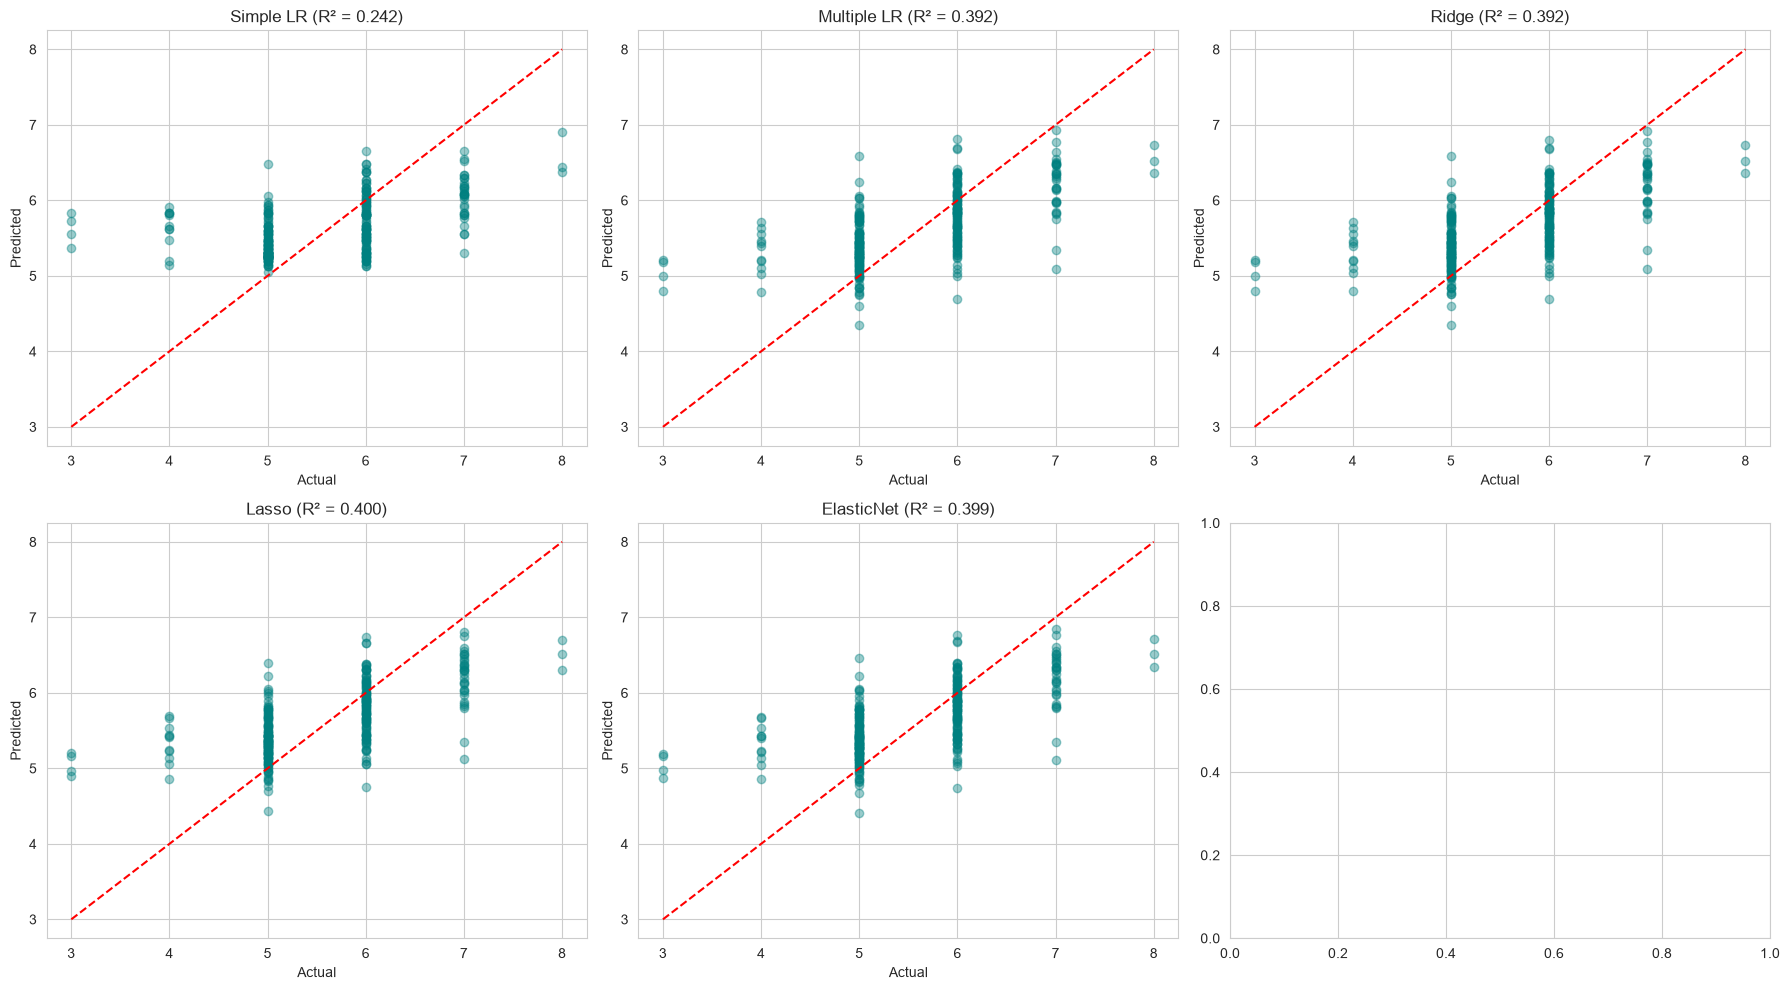

In [22]:
# Unit 3: Visual comparison of predictions

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for idx, (name, (model, X_te)) in enumerate(models.items()):
    row, col = idx // 3, idx % 3
    preds = model.predict(X_te)
    axes[row, col].scatter(y_test, preds, alpha=0.4, color='teal')
    axes[row, col].plot([3, 8], [3, 8], 'r--')
    r2 = r2_score(y_test, preds)
    axes[row, col].set_title(f'{name} (R² = {r2:.3f})')
    axes[row, col].set_xlabel('Actual')
    axes[row, col].set_ylabel('Predicted')

plt.tight_layout()
plt.show()

## Cell 21: Bonus - Classification View (Unit 4) 🎯
Converting quality to binary: **Good (≥7) vs Bad (≤6)** — demonstrates Unit 4 classification algorithms.

In [23]:
# Unit 4: Wine quality can also be treated as classification!
# Convert quality to binary: Good (>=7) vs Bad (<=6)

y_class = (df_clean['quality'] >= 7).astype(int)  # 1 = Good wine, 0 = Not good
print(f"Class distribution:\n{y_class.value_counts()}")
print(f"Good wines (7-8): {y_class.mean()*100:.1f}%")

# Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class)

# Scale
scaler_c = StandardScaler()
X_train_c = scaler_c.fit_transform(X_train_c)
X_test_c = scaler_c.transform(X_test_c)

# Three classification models (Unit 4)
class_models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

class_results = []
for name, model in class_models.items():
    model.fit(X_train_c, y_train_c)
    y_pred = model.predict(X_test_c)
    y_prob = model.predict_proba(X_test_c)[:, 1]

    acc = accuracy_score(y_test_c, y_pred)
    auc = roc_auc_score(y_test_c, y_prob)
    class_results.append({'Model': name, 'Accuracy': round(acc, 4), 
                          'ROC-AUC': round(auc, 4)})
    print(f"\n{name}: Accuracy = {acc:.4f}, ROC-AUC = {auc:.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test_c, y_pred))

print("\nCLASSIFICATION COMPARISON:")
print(pd.DataFrame(class_results).to_string(index=False))

Class distribution:
quality
0    1175
1     184
Name: count, dtype: int64
Good wines (7-8): 13.5%

Logistic Regression: Accuracy = 0.8750, ROC-AUC = 0.8860
Confusion Matrix:
[[229   6]
 [ 28   9]]

KNN: Accuracy = 0.8787, ROC-AUC = 0.8095
Confusion Matrix:
[[224  11]
 [ 22  15]]

Random Forest: Accuracy = 0.8971, ROC-AUC = 0.8652
Confusion Matrix:
[[230   5]
 [ 23  14]]

CLASSIFICATION COMPARISON:
              Model  Accuracy  ROC-AUC
Logistic Regression    0.8750   0.8860
                KNN    0.8787   0.8095
      Random Forest    0.8971   0.8652


## Cell 22: Hyperparameter Tuning & Final Model Selection (Unit 3)

The assignment requires a proper train/validation/test strategy or cross-validation, hyperparameter tuning, and a justified final model. We tune Ridge, Lasso, and Elastic Net with 5-fold cross-validation, select the best model, then **save it to disk** so it can be reused for predictions.

In [24]:
import joblib
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor

# 5-fold cross-validation on the training set (no test leakage)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Four candidate models spanning different algorithm families
candidates = {
    'Ridge': (Ridge(random_state=42),
              {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}),
    'Lasso': (Lasso(random_state=42, max_iter=10000),
              {'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0]}),
    'ElasticNet': (ElasticNet(random_state=42, max_iter=10000),
                   {'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0],
                    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}),
    'RandomForest': (RandomForestRegressor(random_state=42),
                     {'n_estimators': [100, 200], 'max_depth': [None, 5, 10]}),
}

# file names used when saving each trained model
file_names = {
    'Ridge': 'wine_quality_ridge.joblib',
    'Lasso': 'wine_quality_lasso.joblib',
    'ElasticNet': 'wine_quality_elasticnet.joblib',
    'RandomForest': 'wine_quality_randomforest.joblib',
}

tuned = []
fitted_models = {}
for name, (estimator, grid) in candidates.items():
    try:
        gs = GridSearchCV(estimator, grid, cv=kf, scoring='r2', n_jobs=None)
        gs.fit(X_train_scaled, y_train)
        fitted_models[name] = gs.best_estimator_
        pred = gs.predict(X_test_scaled)
        tuned.append({'Model': name,
                      'Best_Params': str(gs.best_params_),
                      'CV_R2': round(gs.best_score_, 4),
                      'Test_R2': round(r2_score(y_test, pred), 4),
                      'Test_RMSE': round(np.sqrt(mean_squared_error(y_test, pred)), 4),
                      'Test_MAE': round(mean_absolute_error(y_test, pred), 4)})
        print(f"{name}: best={gs.best_params_} | CV R2={gs.best_score_:.4f}")
    except Exception as e:
        print(f"{name}: FAILED -> {e}")

tuned_df = pd.DataFrame(tuned)
print()
print("HYPERPARAMETER TUNING RESULTS (5-fold CV)")
print("=" * 90)
print(tuned_df.to_string(index=False))

assert len(tuned_df) >= 3, "At least 3 models must be generated"

# ---- SELECT BEST MODEL (highest CV R2) ----
best_name = tuned_df.loc[tuned_df['CV_R2'].idxmax(), 'Model']
print()
print(f">>> SELECTED FINAL MODEL: {best_name}")

# ---- SAVE ALL 4 TRAINED MODELS ----
for name, model in fitted_models.items():
    joblib.dump(model, file_names[name])
    print(f"Saved: {file_names[name]}")

# Save the best model under a canonical name + the scaler
best_model = fitted_models[best_name]
joblib.dump(best_model, 'wine_quality_model.joblib')
joblib.dump(scaler, 'wine_quality_scaler.joblib')
print("Saved: wine_quality_model.joblib (best), wine_quality_scaler.joblib")

# ---- FINAL COMPARISON TABLE ----
tuned_df['Selected'] = tuned_df['Model'].apply(lambda m: '  <== BEST' if m == best_name else '')
print()
print("FINAL MODEL COMPARISON (sorted by CV R2)")
print("=" * 90)
print(tuned_df.sort_values('CV_R2', ascending=False)[['Model', 'CV_R2', 'Test_R2', 'Test_RMSE', 'Test_MAE', 'Selected']].to_string(index=False))

# Save the comparison table for the report
tuned_df.to_csv('model_comparison.csv', index=False)
print()
print("Saved: model_comparison.csv")

final_pred = best_model.predict(X_test_scaled)
print()
print(f"Final ({best_name}) test performance: "
      f"R2={r2_score(y_test, final_pred):.4f} | "
      f"RMSE={np.sqrt(mean_squared_error(y_test, final_pred)):.4f} | "
      f"MAE={mean_absolute_error(y_test, final_pred):.4f}")

# ---- DEMO: LOAD AND PREDICT ----
loaded_model = joblib.load('wine_quality_model.joblib')
loaded_scaler = joblib.load('wine_quality_scaler.joblib')
sample = pd.DataFrame([{
    'fixed acidity': 7.4, 'volatile acidity': 0.70, 'citric acid': 0.0,
    'residual sugar': 1.9, 'chlorides': 0.076, 'free sulfur dioxide': 11.0,
    'total sulfur dioxide': 34.0, 'density': 0.9978, 'pH': 3.51,
    'sulphates': 0.56, 'alcohol': 9.4
}])
print()
print(f"Demo prediction for a new wine sample: quality = {loaded_model.predict(loaded_scaler.transform(sample))[0]:.2f}")


Ridge: best={'alpha': 100.0} | CV R2=0.3225
Lasso: best={'alpha': 0.01} | CV R2=0.3259
ElasticNet: best={'alpha': 0.01, 'l1_ratio': 0.7} | CV R2=0.3263
RandomForest: best={'max_depth': 10, 'n_estimators': 200} | CV R2=0.3442

HYPERPARAMETER TUNING RESULTS (5-fold CV)
       Model                            Best_Params  CV_R2  Test_R2  Test_RMSE  Test_MAE
       Ridge                       {'alpha': 100.0} 0.3225   0.3957     0.6542    0.5048
       Lasso                        {'alpha': 0.01} 0.3259   0.3995     0.6522    0.5012
  ElasticNet       {'alpha': 0.01, 'l1_ratio': 0.7} 0.3263   0.3989     0.6525    0.5015
RandomForest {'max_depth': 10, 'n_estimators': 200} 0.3442   0.4642     0.6160    0.4689

>>> SELECTED FINAL MODEL: RandomForest
Saved: wine_quality_ridge.joblib
Saved: wine_quality_lasso.joblib
Saved: wine_quality_elasticnet.joblib
Saved: wine_quality_randomforest.joblib
Saved: wine_quality_model.joblib (best), wine_quality_scaler.joblib

FINAL MODEL COMPARISON (sorted by 